# Тищенко Иван ПМ23-1

Реализовать 2D-свёртку вручную на Numpy: stride, padding, несколько ядер.
Реализовать фильтры blur, sharpen, Sobel X/Y через собственные ядра. Сравнить результат с cv2.filter2D или scipy.siganl.convolve2d . Измерить время работы на изображениях разных размеров.

![image.png](https://miro.medium.com/v2/resize:fit:640/format:webp/1*d2Q7BJrDzSQZgLFR4PMgYw.gif)

In [1]:
from pathlib import Path
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from scipy.signal import convolve2d

np.set_printoptions(precision=4, suppress=True)
print("NumPy:", np.__version__)

NumPy: 2.4.6


## Реализовать 2D-свёртку вручную на Numpy: stride, padding, несколько ядер.

In [2]:
def conv2d_numpy(image, kernels, stride=1, padding=0):
    image = np.asarray(image, dtype=np.float32)
    kernels = np.asarray(kernels, dtype=np.float32)

    if kernels.ndim == 2:
        kernels = kernels[None, :, :]

    kernel_h, kernel_w = kernels.shape[1:]

    if padding == "same":
        pad_h = kernel_h // 2
        pad_w = kernel_w // 2
    elif padding == "valid":
        pad_h = 0
        pad_w = 0
    else:
        pad_h = int(padding)
        pad_w = int(padding)

    padded_image = np.pad(
        image,
        ((pad_h, pad_h), (pad_w, pad_w)),
        mode="constant",
    )

    output_h = (padded_image.shape[0] - kernel_h) // stride + 1
    output_w = (padded_image.shape[1] - kernel_w) // stride + 1
    result = np.zeros((len(kernels), output_h, output_w), dtype=np.float32)

    flipped_kernels = kernels[:, ::-1, ::-1]

    for y in range(output_h):
        for x in range(output_w):
            y_start = y * stride
            x_start = x * stride
            fragment = padded_image[
                y_start : y_start + kernel_h,
                x_start : x_start + kernel_w,
            ]
            result[:, y, x] = np.sum(
                fragment * flipped_kernels,
                axis=(1, 2),
            )

    return result

##  Реализовать фильтры blur, sharpen, Sobel X/Y через собственные ядра

In [3]:
FILTERS = {
    "Blur 3×3": np.ones((3, 3), dtype=np.float32) / 9.0,
    "Sharpen": np.array(
        [[0, -1, 0], [-1, 5, -1], [0, -1, 0]], dtype=np.float32
    ),
    "Sobel X": np.array(
        [[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], dtype=np.float32
    ),
    "Sobel Y": np.array(
        [[-1, -2, -1], [0, 0, 0], [1, 2, 1]], dtype=np.float32
    ),
}

kernel_names = list(FILTERS)
kernels = np.stack(list(FILTERS.values()))
print("Форма стека ядер:", kernels.shape)
for name, kernel in FILTERS.items():
    print(f"\n{name}:\n{kernel}")

Форма стека ядер: (4, 3, 3)

Blur 3×3:
[[0.1111 0.1111 0.1111]
 [0.1111 0.1111 0.1111]
 [0.1111 0.1111 0.1111]]

Sharpen:
[[ 0. -1.  0.]
 [-1.  5. -1.]
 [ 0. -1.  0.]]

Sobel X:
[[-1.  0.  1.]
 [-2.  0.  2.]
 [-1.  0.  1.]]

Sobel Y:
[[-1. -2. -1.]
 [ 0.  0.  0.]
 [ 1.  2.  1.]]


In [4]:
image_path = Path('pic.jpg')
image = np.asarray(Image.open(image_path).convert("L"), dtype=np.float32) / 255.0
image_source = str(image_path)

manual_results = conv2d_numpy(image, kernels, stride=1, padding="same")
print(f"Источник: {image_source}; image={image.shape}; result={manual_results.shape}")

Источник: pic.jpg; image=(1169, 822); result=(4, 1169, 822)


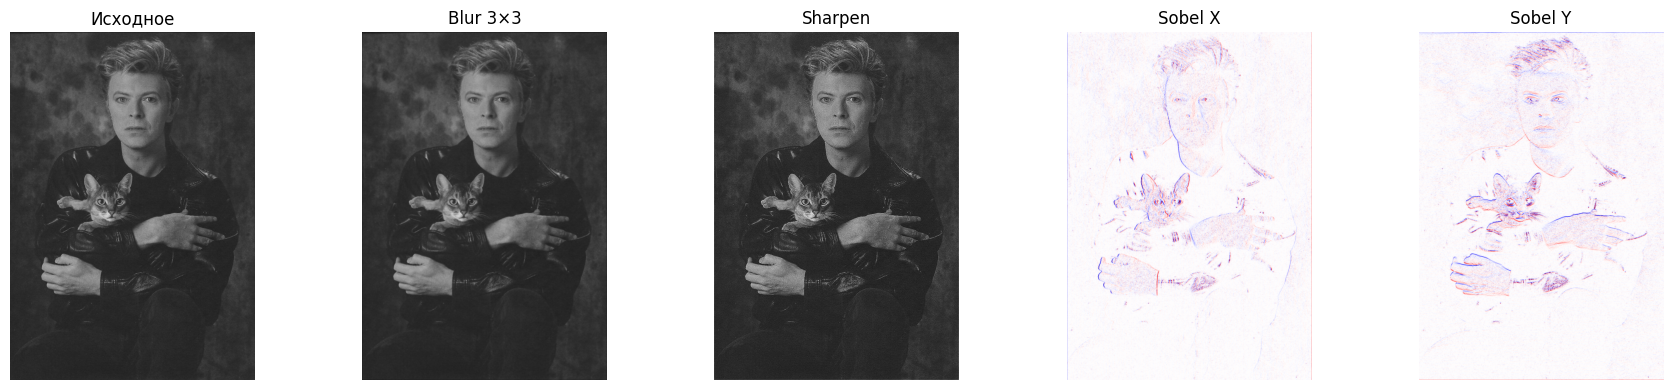

In [5]:
fig, axes = plt.subplots(1, 5, figsize=(18, 4))
axes[0].imshow(image, cmap="gray", vmin=0, vmax=1)
axes[0].set_title("Исходное")

for ax, name, result in zip(axes[1:], kernel_names, manual_results):
    if name.startswith("Sobel"):
        limit = max(float(np.max(np.abs(result))), 1e-12)
        ax.imshow(result, cmap="seismic", vmin=-limit, vmax=limit)
    else:
        ax.imshow(np.clip(result, 0, 1), cmap="gray", vmin=0, vmax=1)
    ax.set_title(name)

for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

Порог: 0.3


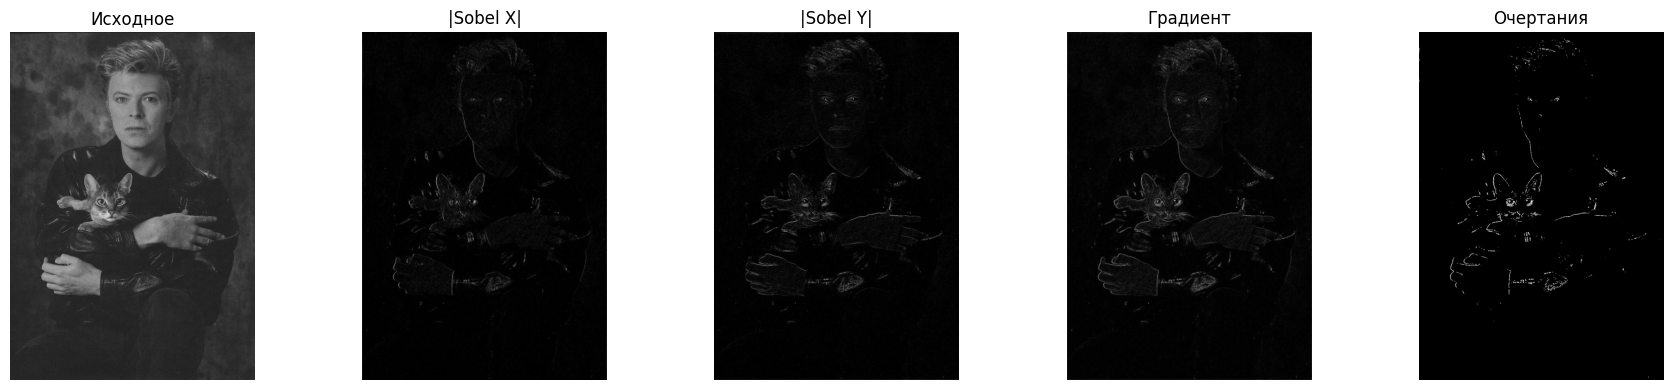

In [6]:
sobel_x = manual_results[kernel_names.index("Sobel X")]
sobel_y = manual_results[kernel_names.index("Sobel Y")]

# Общая сила границы по двум направлениям.
sobel_magnitude = np.sqrt(sobel_x ** 2 + sobel_y ** 2)
sobel_magnitude = sobel_magnitude / sobel_magnitude.max()

# Пиксели с достаточно сильным градиентом считаем очертаниями.
threshold = 0.3
outline_map = sobel_magnitude > threshold

print("Порог:", threshold)

fig, axes = plt.subplots(1, 5, figsize=(18, 4))
axes[0].imshow(image, cmap="gray")
axes[0].set_title("Исходное")
axes[1].imshow(np.abs(sobel_x), cmap="gray")
axes[1].set_title("|Sobel X|")
axes[2].imshow(np.abs(sobel_y), cmap="gray")
axes[2].set_title("|Sobel Y|")
axes[3].imshow(sobel_magnitude, cmap="gray")
axes[3].set_title("Градиент")
axes[4].imshow(outline_map, cmap="gray")
axes[4].set_title("Очертания")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

## 5. Сравнить результат с cv2.filter2D или scipy.siganl.convolve2d

In [7]:
scipy_results = np.stack([
    convolve2d(image, kernel, mode="same", boundary="fill")
    for kernel in kernels
]).astype(np.float32)

for i, name in enumerate(kernel_names):
    difference = np.max(np.abs(manual_results[i] - scipy_results[i]))
    print(f"{name}: максимальная разница = {difference:.8f}")

assert np.allclose(manual_results, scipy_results, atol=1e-5)
print("Результаты совпадают с SciPy.")

Blur 3×3: максимальная разница = 0.00000018
Sharpen: максимальная разница = 0.00000048
Sobel X: максимальная разница = 0.00000036
Sobel Y: максимальная разница = 0.00000054
Результаты совпадают с SciPy.


In [8]:
test_image = np.arange(25, dtype=np.float32).reshape(5, 5)
test_kernels = kernels[:2]

same_result = conv2d_numpy(
    test_image,
    test_kernels,
    stride=1,
    padding="same",
)
stride_result = conv2d_numpy(
    test_image,
    test_kernels,
    stride=2,
    padding="same",
)
valid_result = conv2d_numpy(
    test_image,
    test_kernels,
    stride=1,
    padding="valid",
)

scipy_same = np.stack([
    convolve2d(test_image, kernel, mode="same")
    for kernel in test_kernels
]).astype(np.float32)

assert np.allclose(same_result, scipy_same, atol=1e-5)
assert np.allclose(stride_result, scipy_same[:, ::2, ::2], atol=1e-5)

print("same, stride=1:", same_result.shape)
print("same, stride=2:", stride_result.shape)
print("valid, stride=1:", valid_result.shape)

same, stride=1: (2, 5, 5)
same, stride=2: (2, 3, 3)
valid, stride=1: (2, 3, 3)


##  Измерить время работы на изображениях разных размеров.

In [9]:
def resize_image(image, size):
    image_uint8 = (image * 255).astype(np.uint8)
    resized = Image.fromarray(image_uint8).resize((size, size))
    return np.asarray(resized, dtype=np.float32) / 255.0


def measure_time(function):
    start = perf_counter()
    function()
    return perf_counter() - start


rows = []

for size in (128, 256, 512, 1024):
    sample = resize_image(image, size)

    numpy_time = measure_time(
        lambda: conv2d_numpy(sample, kernels, padding="same")
    )
    scipy_time = measure_time(
        lambda: np.stack([
            convolve2d(sample, kernel, mode="same")
            for kernel in kernels
        ])
    )

    rows.append({
        "размер": f"{size}×{size}",
        "пикселей": size * size,
        "NumPy, мс": numpy_time * 1000,
        "SciPy, мс": scipy_time * 1000,
    })

benchmark = pd.DataFrame(rows)
display(benchmark.round(3))

,размер,пикселей,"NumPy, мс","SciPy, мс"
0,128×128,16384,97.686,1.514
1,256×256,65536,369.205,5.395
2,512×512,262144,1667.516,34.586
3,1024×1024,1048576,6177.387,116.262


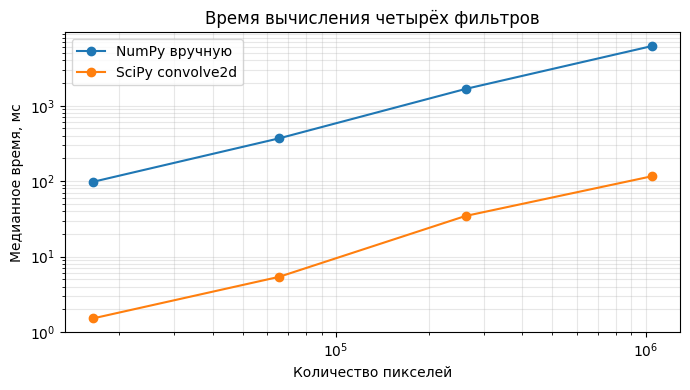

In [10]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(benchmark["пикселей"], benchmark["NumPy, мс"], "o-", label="NumPy вручную")
ax.plot(benchmark["пикселей"], benchmark["SciPy, мс"], "o-", label="SciPy convolve2d")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Количество пикселей")
ax.set_ylabel("Медианное время, мс")
ax.set_title("Время вычисления четырёх фильтров")
ax.grid(True, which="both", alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

Я думаю, что связано с тем, что в scipy функционал оптимизирован с помощью C++ или другого более низкоуровневого языка чем python